# STEP 5. H2 Core EDA

> **H2**: For service categories with a high net-decline risk in neighborhood commercial areas, matching on store scale and foot traffic will narrow the net-decline gap with other service categories.

What we do here is check, before matching, **whether matching is needed and whether it is feasible**.

## Variable roles

| Variable | Source | Role |
|---|---|---|
| `y` | Store-commercial area (openings and closures) | Outcome |
| `service_name` | Store-commercial area | Treatment |
| `log_store_count` | Store-commercial area `store_count` | **Matching covariate ①** ★ stated in H2 |
| `log_foot_traffic` | Street-level population-commercial area | **Matching covariate ②** ★ stated in H2 |
| `log_area_size` | Area-commercial area | Matching covariate ③ |
| `log_attracting_facilities` | Attracting facilities-commercial area | Matching covariate ④ |

## Sequence

5-1 Choose the treated group → **5-2 Stability of the treated-group choice** → 5-3 Raw gap → 5-4 Scale confounding diagnosis → 5-5 SMD → 5-6 Common support → 5-7 Cross-sectional test

> In STEP 4, the gap between rank 1 (Korean restaurants) and rank 2 (coffee-beverages) was narrow, at **0.9 percentage points (pp)**. Because the design lets the data choose the treated group, we first check in 5-2 **how well that choice withstands sampling variation**. If it is weak, the later ATT is not "the effect of Korean restaurants" but "the effect of whichever service category happened to rank first".

In [1]:
import sys, os
from pathlib import Path

# Find the project root wherever the notebook is opened and add it to sys.path
ROOT = Path.cwd()
while not (ROOT / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import numpy as np
import pandas as pd
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
print("Project root:", ROOT.name)

Project root: seoul-closure-risk


In [2]:
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from config import PROC, FIG, TARGET_TYPE, COVARIATES, SEED, stable_rank, set_plot_style
set_plot_style()
OUT = FIG.parent

def smd(a, b):
    """Standardized mean difference. Balanced if |SMD| < 0.1"""
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)

d = pd.read_pickle(PROC / "03_panel.pkl")
d = d.drop(columns=[c for c in ["sales_missing_flag"] if c in d.columns])

gm = d[d["area_type"] == TARGET_TYPE].copy()
print(f"{TARGET_TYPE} food-service sample {len(gm):,} rows | net-decline rate {gm['y'].mean():.1%}")
print(f"{gm['area_code'].nunique()} commercial areas · {gm['quarter_code'].nunique()} quarters")

neighborhood commercial area food-service sample 34,647 rows | net-decline rate 23.6%
928 commercial areas · 12 quarters


## 5-1. Net-decline rate by service category → choose the treated group

We do not fix the treated group in advance; we **let the data pick it**, to avoid any impression of an arbitrary choice.

In [3]:
t = (gm.groupby("service_name")
     .agg(net_decline_rate=("y", "mean"), n_cells=("y", "size"),
          mean_stores=("store_count", "mean"), median_foot_traffic=("foot_traffic_total", "median"),
          mean_franchise_share=("franchise_share", "mean"))
     .sort_values("net_decline_rate", ascending=False))
display(t.round(3))

TREAT = t.index[0]
gm["treated"] = (gm["service_name"] == TREAT).astype(int)
margin = t.iloc[0]["net_decline_rate"] - t.iloc[1]["net_decline_rate"]
print(f"→ Treated group: {TREAT} ({t.iloc[0]['net_decline_rate']:.1%})")
print(f"   Rank 2 {t.index[1]} ({t.iloc[1]['net_decline_rate']:.1%}), gap {(margin)*100:+.1f} pp")

,net_decline_rate,n_cells,mean_stores,median_foot_traffic,mean_franchise_share
service_name,,,,,
Korean restaurants,0.253,9957,21.315,779241.0,0.097
Coffee and beverages,0.244,7741,12.595,893978.0,0.181
Beer and casual pubs,0.239,4596,11.783,1170658.0,0.092
Fast-food restaurants,0.237,1440,7.090,1515928.5,0.502
Western restaurants,0.228,1478,11.118,1305611.5,0.068
Korean snack-food restaurants,0.222,3634,8.234,1264523.0,0.201
Japanese restaurants,0.216,1036,8.420,1549588.5,0.122
Bakeries,0.206,1636,7.411,1319055.5,0.161
Fried-chicken shops,0.201,1922,6.703,1391462.5,0.642


→ Treated group: Korean restaurants (25.3%)
   Rank 2 Coffee and beverages (24.4%), gap +0.9 pp


## 5-2. Stability of the treated-group choice ★

If the gap between rank 1 and rank 2 is narrow, the "treated group chosen by the data" may effectively be due to chance. We check in two ways.

- **Rank 1 by quarter** — who ranks first in each of the 12 quarters
- **Cluster bootstrap** — resample commercial areas with replacement and re-rank 1,000 times: who ranks first, and how often (the same commercial area is observed repeatedly over 12 quarters, so we resample at the commercial-area level)

In [4]:
# ① Rank 1 by quarter
per_q = (gm.groupby(["quarter_code", "service_name"])["y"].mean()
         .unstack())
winner = per_q.idxmax(axis=1)
display(pd.DataFrame({"Rank-1 service category": winner,
                      "Rank-1 net-decline rate": per_q.max(axis=1).round(3),
                      f"{TREAT} rank": per_q.rank(axis=1, ascending=False, method="min")[TREAT].astype(int)}))
print(f"Quarters where {TREAT} ranks first : {(winner == TREAT).sum()} / {len(winner)}")

,Rank-1 service category,Rank-1 net-decline rate,Korean restaurants rank
quarter_code,,,
20231,Korean restaurants,0.287,1
20232,Fast-food restaurants,0.284,3
20233,Western restaurants,0.268,3
20234,Bakeries,0.252,10
20241,Western restaurants,0.283,6
20242,Fast-food restaurants,0.309,4
20243,Coffee and beverages,0.290,7
20244,Fast-food restaurants,0.322,2
20251,Korean restaurants,0.292,1


Quarters where Korean restaurants ranks first : 3 / 12


In [5]:
# ② Commercial-area-level cluster bootstrap
rng = np.random.default_rng(SEED)
areas = np.unique(gm["area_code"].to_numpy())
pos = {a: idx.to_numpy() for a, idx in gm.groupby("area_code").groups.items()}
yv  = gm["y"].to_numpy()
svc = gm["service_name"].to_numpy()

wins, top2 = {}, {}
B = 1000
for _ in range(B):
    sel = np.concatenate([pos[a] for a in rng.choice(areas, len(areas), replace=True)])
    loc = gm.index.get_indexer(sel)
    s = pd.Series(yv[loc]).groupby(svc[loc]).mean().sort_values(ascending=False)
    wins[s.index[0]] = wins.get(s.index[0], 0) + 1
    for nm in s.index[:2]:
        top2[nm] = top2.get(nm, 0) + 1

res = pd.DataFrame({"Rank-1 frequency": pd.Series(wins), "Top-2 frequency": pd.Series(top2)}).fillna(0)
res = (res / B).sort_values("Rank-1 frequency", ascending=False)
display(res.round(3))
print(f"Bootstrap {B} runs | {TREAT} rank-1 share {res.loc[TREAT, 'Rank-1 frequency']:.1%}")
print("\n※ If the rank-1 share is low, do not conclude the ATT is 'the effect of this service category';")
print("   widen the scope and report it as 'the effect of top-ranked net-decline service categories'.")

,Rank-1 frequency,Top-2 frequency
Korean restaurants,0.783,0.956
Fast-food restaurants,0.088,0.238
Coffee and beverages,0.061,0.502
Beer and casual pubs,0.039,0.203
Western restaurants,0.025,0.090
Japanese restaurants,0.004,0.011


Bootstrap 1000 runs | Korean restaurants rank-1 share 78.3%

※ If the rank-1 share is low, do not conclude the ATT is 'the effect of this service category';
   widen the scope and report it as 'the effect of top-ranked net-decline service categories'.


### ③ Size of the selection effect — permutation test ★

The two checks above only look at "does rank 1 wobble". A more uncomfortable question remains.

**Even if the true difference between service categories is exactly 0, the best of 10 will come out above the overall mean.**
With a finite sample, some service categories jump up by chance, and we pick the best of them. If we do not measure this "gap created by the act of selection itself", we will mistake the entire raw gap in 5-3 for a real difference between service categories.

**Method** — Randomly shuffling the label `y` completely breaks the relationship between service category and net decline (the null hypothesis). The sample size of each service category stays the same. Measuring `net-decline rate of the best category − overall mean` 1,000 times in this state, the average is the pure selection effect.

In [6]:
rng_p   = np.random.default_rng(SEED)
yv_all  = gm["y"].to_numpy()
svc_all = gm["service_name"].to_numpy()
grand   = yv_all.mean()

obs_max = pd.Series(yv_all).groupby(svc_all).mean().max() - grand

B_PERM   = 1000
null_max = np.empty(B_PERM)
for b in range(B_PERM):
    null_max[b] = pd.Series(rng_p.permutation(yv_all)).groupby(svc_all).mean().max() - grand

sel_effect = null_max.mean()
p_perm     = (null_max >= obs_max).mean()

print(f"Observed  rank-1 category ({TREAT}) − overall mean = {obs_max*100:+.2f} pp")
print(f"Null      gap that 'the best of 10' produces by itself = {sel_effect*100:+.2f} pp")
print(f"      null distribution 95% range {np.quantile(null_max,.025)*100:+.2f} ~ {np.quantile(null_max,.975)*100:+.2f} pp")
print(f"Permutation p-value = {p_perm:.4f}   (probability that shuffled data spreads as far as observed)")
print()
print(f"→ About {sel_effect/obs_max:.0%} of the observed gap is explained by the act of 'picking the best' alone.")
print(f"   The substantive service-category difference after removing the selection effect is about {(obs_max-sel_effect)*100:+.2f} pp.")
print()

# Match the scale of the 'Korean restaurants vs rest' gap in 5-3.
#   The value above is (rank 1 − overall mean), and the overall mean includes rank 1 itself.
#   Since overall mean = w·treated + (1−w)·control,  (rank 1 − overall mean) = (1−w)·(treated − control).
#   So to move to the 'treated − control' scale, divide by (1−w).
w_tr = (svc_all == TREAT).mean()
sel_vs_rest = sel_effect / (1 - w_tr)
print(f"[Scale conversion] treated share w={w_tr:.3f} → selection effect on the 'Korean restaurants vs rest' scale "
      f"= {sel_effect*100:.2f} / (1-{w_tr:.3f}) = {sel_vs_rest*100:+.2f} pp")
print()
print("※ The raw gap in 5-3 must always be read together with this value.")
print("※ The ATT is computed within matched pairs, so it is not affected by this bias.")

perm_note = dict(observed=obs_max, selection_effect=sel_effect, selection_effect_vs_rest=sel_vs_rest,
                 substantive=obs_max - sel_effect, p=p_perm)

Observed  rank-1 category (Korean restaurants) − overall mean = +1.70 pp
Null      gap that 'the best of 10' produces by itself = +1.49 pp
      null distribution 95% range +0.53 ~ +2.94 pp
Permutation p-value = 0.3440   (probability that shuffled data spreads as far as observed)

→ About 88% of the observed gap is explained by the act of 'picking the best' alone.
   The substantive service-category difference after removing the selection effect is about +0.21 pp.

[Scale conversion] treated share w=0.287 → selection effect on the 'Korean restaurants vs rest' scale = 1.49 / (1-0.287) = +2.10 pp

※ The raw gap in 5-3 must always be read together with this value.
※ The ATT is computed within matched pairs, so it is not affected by this bias.


## 5-3. Raw gap before matching

H2 predicts that this value shrinks after matching.

> ⚠️ Remember the permutation test just above. A large part of the gap below is created by **the act of selecting the service category with the highest net-decline rate as the treated group**, not by a real difference between service categories.

In [7]:
p1 = gm.loc[gm["treated"] == 1, "y"].mean()
p0 = gm.loc[gm["treated"] == 0, "y"].mean()
gap = p1 - p0
print(f"Treated {TREAT}    n={int(gm['treated'].sum()):,}   net-decline rate {p1:.1%}")
print(f"Control  other food-service   n={int((1-gm['treated']).sum()):,}  net-decline rate {p0:.1%}")
print(f"\nRaw gap = {(gap)*100:+.1f} pp")
print(f"  ├ Selection effect (permutation test, converted to the same scale) about {perm_note['selection_effect_vs_rest']*100:+.2f} pp")
print(f"  └ Removing it leaves a substantive gap of about {gap*100 - perm_note['selection_effect_vs_rest']*100:+.2f} pp")
print(f"\n⚠️ Permutation p-value {perm_note['p']:.3f} — the fact that 'Korean restaurants rank first' is itself not significant.")
print("   That is, the pre-matching gap is almost entirely a product of selection rather than a phenomenon to be explained.")
print("   Even so, if the post-matching gap opens up clearly negative, that is the real signal.")

Treated Korean restaurants    n=9,957   net-decline rate 25.3%
Control  other food-service   n=24,690  net-decline rate 22.9%

Raw gap = +2.4 pp
  ├ Selection effect (permutation test, converted to the same scale) about +2.10 pp
  └ Removing it leaves a substantive gap of about +0.29 pp

⚠️ Permutation p-value 0.344 — the fact that 'Korean restaurants rank first' is itself not significant.
   That is, the pre-matching gap is almost entirely a product of selection rather than a phenomenon to be explained.
   Even so, if the post-matching gap opens up clearly negative, that is the real signal.


## 5-4. Scale confounding diagnosis

The gap may come from differences in scale rather than from risk specific to the service category. We look at how the gap changes **when the scale band is held fixed** — a preview of matching.

In [8]:
r = np.corrcoef(t["mean_stores"], t["net_decline_rate"])[0, 1]
print(f"Correlation of category mean store count ↔ net-decline rate r = {r:+.3f}")
print("A high r suggests 'scale differences' rather than 'service-category-specific risk' → supports H2\n")

gm["size_band"] = pd.qcut(stable_rank(gm, "log_store_count"), 5,
                        labels=[f"Q{i}" for i in range(1, 6)])
piv = gm.pivot_table(index="size_band", columns="treated", values="y",
                     aggfunc=["mean", "size"], observed=True)
tbl = pd.DataFrame({
    "control_net_decline_rate": piv[("mean", 0)], "treated_net_decline_rate": piv[("mean", 1)],
    "control_n": piv[("size", 0)].astype("Int64"), "treated_n": piv[("size", 1)].astype("Int64")})
tbl["gap"] = tbl["treated_net_decline_rate"] - tbl["control_net_decline_rate"]
display(tbl.round(3))
print(f"Raw gap {(gap)*100:+.1f} pp → mean within-band gap {(tbl['gap'].mean())*100:+.1f} pp")
print("※ If the gap shrinks or reverses within bands, it signals that the raw gap is a product of scale confounding")

Correlation of category mean store count ↔ net-decline rate r = +0.657
A high r suggests 'scale differences' rather than 'service-category-specific risk' → supports H2



,control_net_decline_rate,treated_net_decline_rate,control_n,treated_n,gap
size_band,,,,,
Q1,0.153,0.107,6207,723,-0.047
Q2,0.184,0.142,5910,1019,-0.042
Q3,0.226,0.162,5453,1476,-0.064
Q4,0.304,0.242,4599,2330,-0.062
Q5,0.389,0.338,2521,4409,-0.051


Raw gap +2.4 pp → mean within-band gap -5.3 pp
※ If the gap shrinks or reverses within bands, it signals that the raw gap is a product of scale confounding


## 5-5. Covariate balance (SMD)

Criteria: |SMD| < 0.1 balanced / 0.1-0.25 imbalanced / above 0.25 severe

A large SMD **before** matching is itself evidence that "the two groups were originally distributed under different conditions", and is the reason PSM is needed. Only when all covariates fall below 0.1 **after** matching can we say "the conditions have been matched".

In [9]:
rows = []
for c in COVARIATES:
    a = gm.loc[gm["treated"] == 1, c]
    b = gm.loc[gm["treated"] == 0, c]
    s = smd(a, b)
    rows.append({"covariate": c, "treated_mean": a.mean(), "control_mean": b.mean(), "SMD": s,
                 "verdict": "balanced" if abs(s) < 0.1 else ("imbalanced" if abs(s) < 0.25 else "severely imbalanced")})
bal = pd.DataFrame(rows)
display(bal.round(3))
bal.to_csv(OUT / "h2_balance_before.csv", index=False, encoding="utf-8-sig")
print(f"[Saved] outputs/h2_balance_before.csv")

,covariate,treated_mean,control_mean,SMD,verdict
0,log_store_count,2.790,2.158,0.999,severely imbalanced
1,log_foot_traffic,13.410,13.824,-0.447,severely imbalanced
2,log_area_size,11.345,11.653,-0.473,severely imbalanced
3,log_attracting_facilities,2.515,2.841,-0.461,severely imbalanced


[Saved] outputs/h2_balance_before.csv


## 5-6. Common support

For matching to be feasible, the value ranges of the treated and control groups must overlap. Observations in non-overlapping ranges are discarded in PSM.

**Because "the gap narrowed" may really mean "we discarded the observations that created the gap"**, always report the remaining sample size and representativeness after matching.

In [10]:
for c in COVARIATES:
    a = gm.loc[gm["treated"] == 1, c]; b = gm.loc[gm["treated"] == 0, c]
    lo, hi = max(a.min(), b.min()), min(a.max(), b.max())
    keep = ((gm[c] >= lo) & (gm[c] <= hi)).mean()
    print(f"  {c:12} overlap range [{lo:6.2f}, {hi:6.2f}]  → {keep:.1%} of sample included")

  log_store_count overlap range [  1.61,   4.82]  → 100.0% of sample included
  log_foot_traffic overlap range [  2.20,  15.76]  → 100.0% of sample included
  log_area_size overlap range [  9.12,  13.20]  → 99.9% of sample included
  log_attracting_facilities overlap range [  0.00,   4.17]  → 100.0% of sample included


## 5-7. Cross-sectional chi-square + Cramér's V

If all quarters are pooled, the same commercial area is observed up to 12 times and the sample size is artificially inflated. Then even tiny differences come out "significant". So we test on **only the most recent quarter**.

However small p is, if V is small the substantive difference is small.

In [11]:
last_q = gm["quarter_code"].max()
one = gm[gm["quarter_code"] == last_q]
ct = pd.crosstab(one["treated"], one["y"])
chi2, p, dof, _ = chi2_contingency(ct, correction=False)
v = np.sqrt(chi2 / ct.values.sum())

print(f"Cross-section quarter {last_q}   n={ct.values.sum():,}")
display(ct)
print(f"chi2({dof}) = {chi2:.2f},  p = {p:.3g},  Cramér's V = {v:.3f}")
print(f"Cross-sectional gap {(one.loc[one['treated']==1,'y'].mean()-one.loc[one['treated']==0,'y'].mean())*100:+.1f} pp")

Cross-section quarter 20254   n=2,772


y,0,1
treated,,
0,1516,428
1,615,213


chi2(1) = 4.49,  p = 0.0341,  Cramér's V = 0.040
Cross-sectional gap +3.7 pp


## 5-8. Visualization

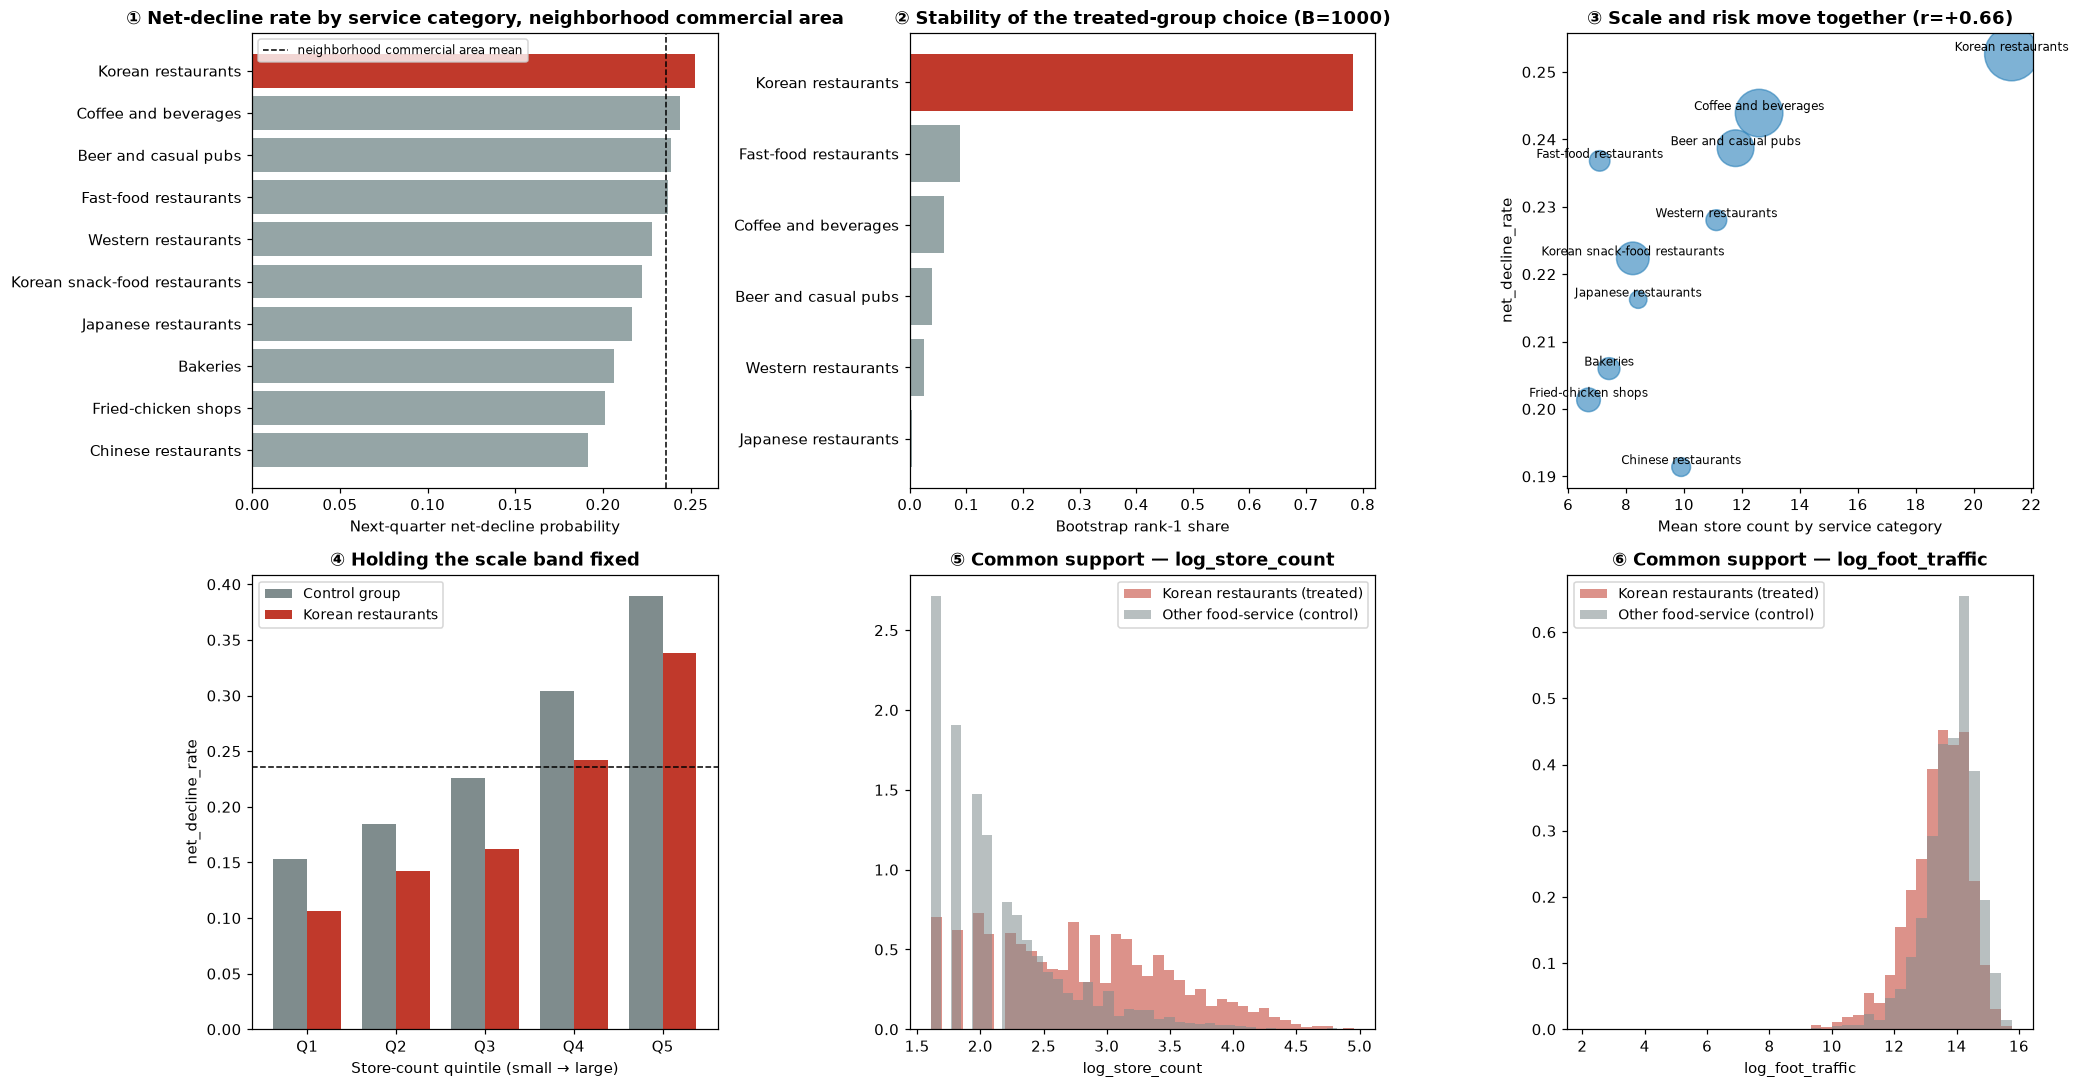

In [12]:
fig, ax = plt.subplots(2, 3, figsize=(19, 10))

# ① Net-decline rate by service category
t2 = t.sort_values("net_decline_rate")
colors = ["#c0392b" if i == TREAT else "#95a5a6" for i in t2.index]
ax[0,0].barh(t2.index, t2["net_decline_rate"], color=colors)
ax[0,0].axvline(gm["y"].mean(), ls="--", c="k", lw=1, label=f"{TARGET_TYPE} mean")
ax[0,0].set_title(f"① Net-decline rate by service category, {TARGET_TYPE}", weight="bold")
ax[0,0].set_xlabel("Next-quarter net-decline probability"); ax[0,0].legend(fontsize=8)

# ② Stability of the treated-group choice
rs = res["Rank-1 frequency"].sort_values()
rs = rs[rs > 0]
ax[0,1].barh(rs.index, rs.values,
             color=["#c0392b" if i == TREAT else "#95a5a6" for i in rs.index])
ax[0,1].set_xlabel("Bootstrap rank-1 share")
ax[0,1].set_title(f"② Stability of the treated-group choice (B={B})", weight="bold")

# ③ Scale and risk
ax[0,2].scatter(t["mean_stores"], t["net_decline_rate"], s=t["n_cells"]/8, alpha=.6, c="#2980b9")
for i, row in t.iterrows():
    ax[0,2].annotate(i, (row["mean_stores"], row["net_decline_rate"]), fontsize=8, ha="center", va="bottom")
ax[0,2].set_xlabel("Mean store count by service category"); ax[0,2].set_ylabel("net_decline_rate")
ax[0,2].set_title(f"③ Scale and risk move together (r={r:+.2f})", weight="bold")

# ④ Gap by scale band
x = np.arange(len(tbl)); w = 0.38
ax[1,0].bar(x - w/2, tbl["control_net_decline_rate"], w, label="Control group", color="#7f8c8d")
ax[1,0].bar(x + w/2, tbl["treated_net_decline_rate"], w, label=f"{TREAT}", color="#c0392b")
ax[1,0].axhline(gm["y"].mean(), ls="--", c="k", lw=1)
ax[1,0].set_xticks(x); ax[1,0].set_xticklabels(tbl.index)
ax[1,0].set_xlabel("Store-count quintile (small → large)"); ax[1,0].set_ylabel("net_decline_rate")
ax[1,0].set_title("④ Holding the scale band fixed", weight="bold"); ax[1,0].legend(fontsize=9)

# ⑤⑥ Common support
for k, c in enumerate(["log_store_count", "log_foot_traffic"]):
    a = ax[1, 1+k]
    for lab, sub, col in [(f"{TREAT} (treated)", gm[gm["treated"]==1], "#c0392b"),
                          ("Other food-service (control)", gm[gm["treated"]==0], "#7f8c8d")]:
        a.hist(sub[c], bins=40, alpha=.55, density=True, label=lab, color=col)
    a.set_title(f"{'⑤' if k==0 else '⑥'} Common support — {c}", weight="bold")
    a.set_xlabel(c); a.legend(fontsize=9)

plt.tight_layout()
plt.savefig(FIG / "step5_h2_eda.png", dpi=130)
plt.show()

## 5-9. Saving and what is handed to STEP 6

In [13]:
gm.to_pickle(PROC / "05_golmok.pkl")
mb = (PROC / "05_golmok.pkl").stat().st_size / 1024**2
print(f"[Saved] 05_golmok.pkl  {gm.shape}  {mb:.1f} MB  ← input to STEP 6 (PSM)")
print(f"[Saved] figures/step5_h2_eda.png\n")

print("── Handed to STEP 6 ──────────────")
print(f"  Treated group          : {TREAT}  (bootstrap rank-1 share {res.loc[TREAT,'Rank-1 frequency']:.1%})")
print(f"  Raw gap before matching: {(gap)*100:+.1f} pp")
print(f"  Max |SMD|              : {bal['SMD'].abs().max():.3f} ({bal.loc[bal['SMD'].abs().idxmax(),'covariate']})")
print(f"  Common support status  : all 4 covariates checked")
print()
print("H2 test: after matching brings all the SMDs above below 0.1,")
print(f"              we see how the raw gap {(gap)*100:+.1f} pp changes.")

[Saved] 05_golmok.pkl  (34647, 36)  8.9 MB  ← input to STEP 6 (PSM)
[Saved] figures/step5_h2_eda.png

── Handed to STEP 6 ──────────────
  Treated group          : Korean restaurants  (bootstrap rank-1 share 78.3%)
  Raw gap before matching: +2.4 pp
  Max |SMD|              : 0.999 (log_store_count)
  Common support status  : all 4 covariates checked

H2 test: after matching brings all the SMDs above below 0.1,
              we see how the raw gap +2.4 pp changes.


---

## What to do in STEP 6

- Estimate propensity scores (4 covariates + quarter dummies) → common-support trimming
- 1:1 nearest-neighbor matching within quarter (caliper 0.2·SD, without replacement)
- **Post-matching SMD balance check** — if it fails, do not interpret the ATT
- ATT + McNemar + commercial-area-level cluster bootstrap
- Diagnosis of treated units that failed to match, sensitivity analysis (caliper, replacement, seed, district fixed effects)